# multimodel_analysis - Phase 6: clustering (unsupervised learning)
`MultiModelClusterer` does for clustering what `MultiModelClassifier` does for classification: it runs many algorithms on the same data, scores them, and tells you which one fits best.

There is **no target and no train/test split** here, so models are judged with *internal* scores:

| score | meaning | better |
|---|---|---|
| Silhouette | how well each row fits its own cluster vs. the next closest (-1 to 1) | higher |
| Calinski-Harabasz | between-cluster vs. within-cluster spread | higher |
| Davies-Bouldin | how similar clusters are to each other | lower |

If you *do* know the true groups you can pass them as `y`; they are never used for fitting, only to add *external* scores (ARI, NMI, ...), which is perfect for learning how well each algorithm recovers the truth.

In [1]:
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris, make_blobs, make_moons
import multimodel_analysis as mm
from multimodel_analysis import MultiModelClusterer
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
print('multimodel_analysis', mm.__version__)

multimodel_analysis 0.5.0


## 1. What is available?

In [2]:
print('standard set :', MultiModelClusterer.default_models())
print()
print('everything    :', MultiModelClusterer.available_models())

standard set : ['kmeans', 'minibatch_kmeans', 'agglomerative', 'gaussian_mixture', 'birch', 'spectral', 'dbscan']

everything    : ['kmeans', 'minibatch_kmeans', 'agglomerative', 'gaussian_mixture', 'birch', 'spectral', 'dbscan', 'bisecting_kmeans', 'agglomerative_average', 'agglomerative_complete', 'hdbscan', 'optics', 'mean_shift', 'affinity_propagation']


## 2. First run: three blobs
`make_blobs` gives us data where we know the truth, so we pass `y` to see external scores too.

In [3]:
X, y = make_blobs(n_samples=450, centers=3, cluster_std=1.0, random_state=11)
X = pd.DataFrame(X, columns=['feature 1', 'feature 2'])
cl = MultiModelClusterer(X, y=y, n_clusters=3, random_state=0, verbose=False)
models = cl.run_all_models()
df = cl.show_tabular_report(models, return_df=True)


 CLUSTERING MODEL COMPARISON 
               Model  Clusters  Noise Points  Silhouette  Calinski-Harabasz  Davies-Bouldin    ARI    NMI  V-measure  Homogeneity  Completeness  Fit Time (s)
              DBSCAN         3            16      0.6106          2671.8859          0.6112 0.9142 0.8720     0.8720       0.9174        0.8309        0.0159
 Spectral Clustering         3             0      0.5904          2410.4525          0.6530 0.9606 0.9405     0.9405       0.9405        0.9405        0.0364
    Gaussian Mixture         3             0      0.5898          2401.4931          0.6543 0.9671 0.9488     0.9488       0.9488        0.9488        0.0106
              KMeans         3             0      0.5892          2430.2814          0.6508 0.9167 0.8918     0.8918       0.8918        0.8918        0.0820
    MiniBatch KMeans         3             0      0.5892          2430.2814          0.6508 0.9167 0.8918     0.8918       0.8918        0.8918        0.0206
               Birch 

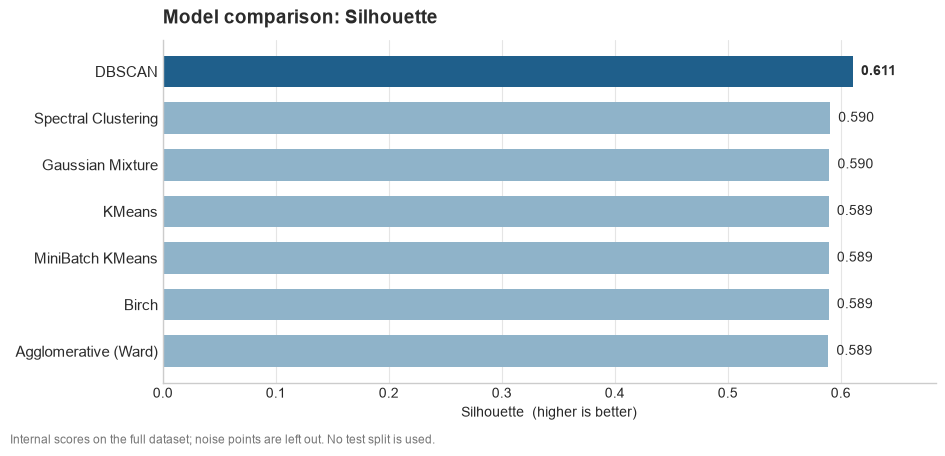

In [4]:
cl.plot_comparison(models)

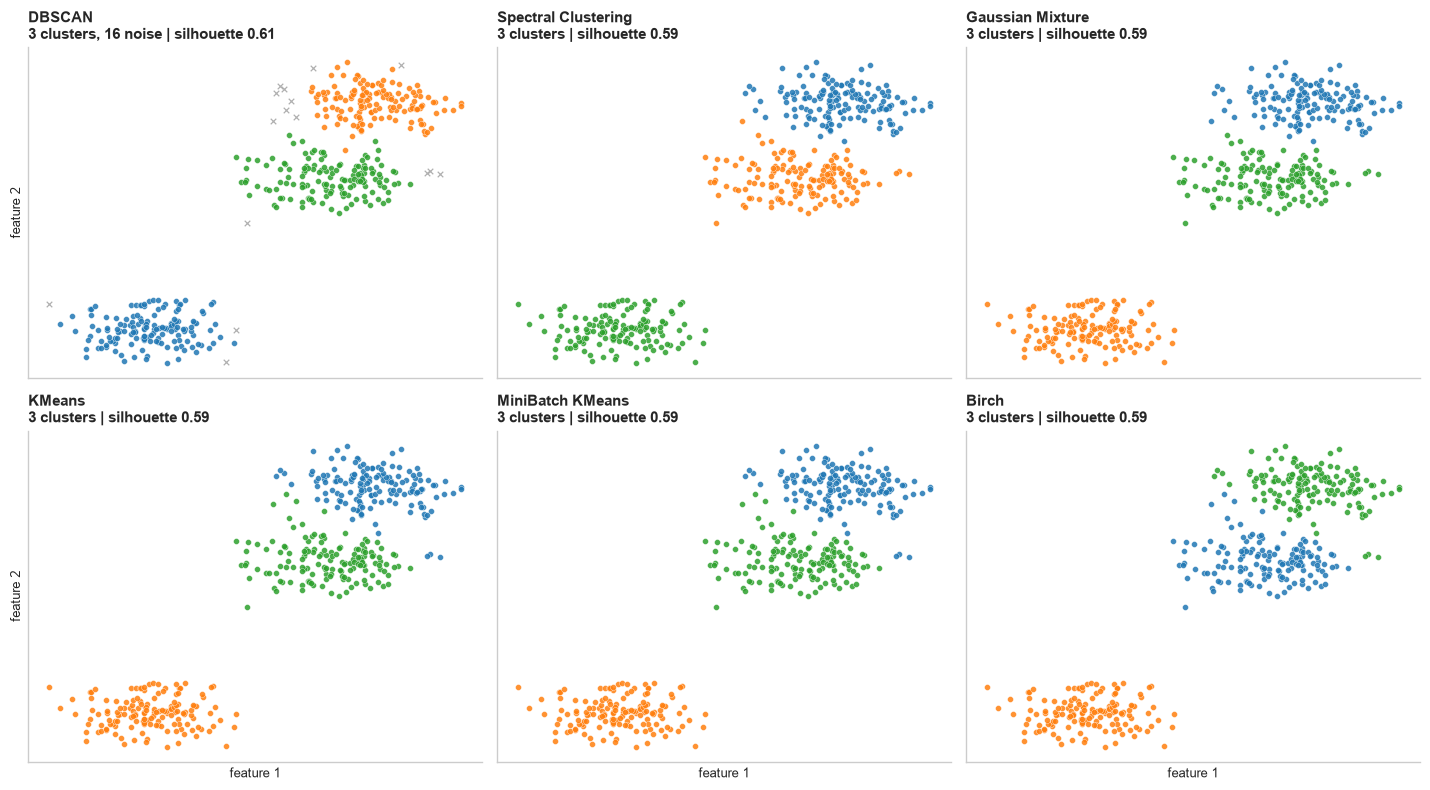

In [5]:
cl.plot_clusters(models)

### Which model labels which row?
`assign_clusters()` returns your data with a `cluster` column; `cluster_profile()` explains each cluster in your original units.

In [6]:
cl.assign_clusters('KMeans').head()

,feature 1,feature 2,cluster
0,-5.707294,-11.433505,1
1,-6.443309,-7.818964,1
2,-8.078717,-10.796250,1
3,0.302978,4.053089,0
4,-0.418644,5.019472,0


In [7]:
cl.cluster_profile('KMeans')

,Size,Share (%),feature 1,feature 2
cluster,,,,
0,151,33.6,-0.605241,4.365643
1,150,33.3,-6.417879,-9.575099
2,149,33.1,-1.819327,-0.206531


## 3. How many clusters? `find_optimal_k` and `n_clusters='auto'`
Often you do not know k. `find_optimal_k()` fits KMeans for k = 2..10 and picks the best silhouette; the plot shows the *elbow* in the inertia curve.

In [8]:
ks = cl.find_optimal_k()

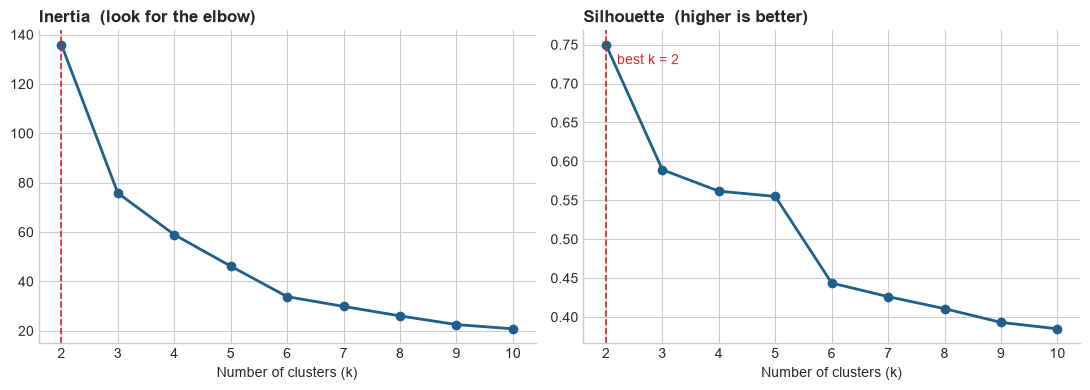

In [9]:
cl.plot_k_search()

Here silhouette prefers k=2: two of the three blobs touch, so merging them scores higher than splitting them. That is a real property of the score, not a bug - which is why the report also shows Calinski-Harabasz and Davies-Bouldin, and why you should look at the plots before trusting a single number. When you have domain knowledge, pass `n_clusters=3` yourself.

In [10]:
auto = MultiModelClusterer(X, n_clusters='auto', random_state=0, verbose=True)
auto_models = auto.run_all_models(include=['kmeans', 'gaussian_mixture', 'agglomerative'])
print('chosen k =', auto.n_clusters_)

[INFO] n_clusters='auto' -> using k=2 (best silhouette).
chosen k = 2


### Silhouette per row
Long bars past the dashed average line mean a row sits well inside its cluster; short or negative bars are rows that may belong elsewhere.

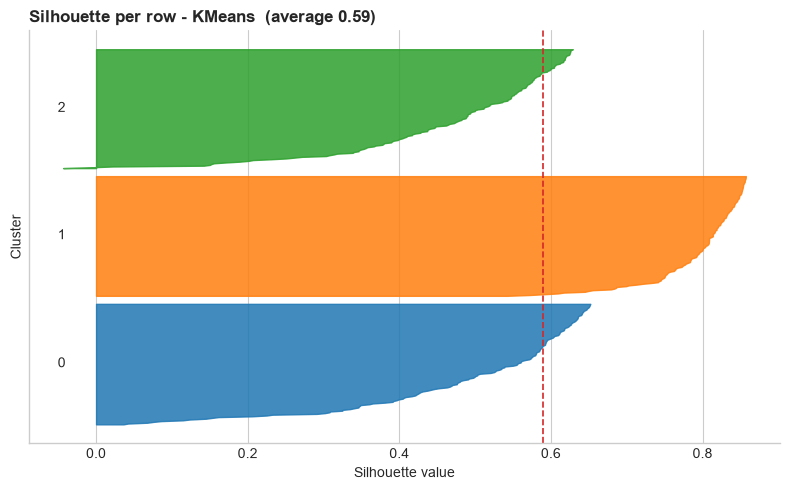

In [11]:
cl.plot_silhouette('KMeans')

## 4. Real data: the iris flowers (4 features)
With more than two features, `plot_clusters` shows the data on its first two principal components (the axis labels say how much variance each keeps). We pass the species as `y` only to check how well the algorithms rediscover them.

In [12]:
iris = load_iris(as_frame=True)
ic = MultiModelClusterer(iris.data, y=iris.target, n_clusters=3, random_state=0, verbose=False)
im = ic.run_all_models(include='all')
idf = ic.show_tabular_report(im, return_df=True, sort_by='ARI')


 CLUSTERING MODEL COMPARISON 
                   Model  Clusters  Noise Points  Silhouette  Calinski-Harabasz  Davies-Bouldin    ARI    NMI  V-measure  Homogeneity  Completeness  Fit Time (s)
        Gaussian Mixture         3             0      0.3742           187.7745          1.0809 0.9039 0.8997     0.8997       0.8983        0.9011        0.0436
                   Birch         3             0      0.4536           219.8188          0.8218 0.6614 0.7331     0.7331       0.7140        0.7532        0.0019
     Spectral Clustering         3             0      0.4593           229.6799          0.8224 0.6465 0.6838     0.6838       0.6737        0.6941        0.0432
                  KMeans         3             0      0.4599           241.9044          0.8336 0.6201 0.6595     0.6595       0.6591        0.6598        0.0210
        MiniBatch KMeans         3             0      0.4599           241.9044          0.8336 0.6201 0.6595     0.6595       0.6591        0.6598        0.06

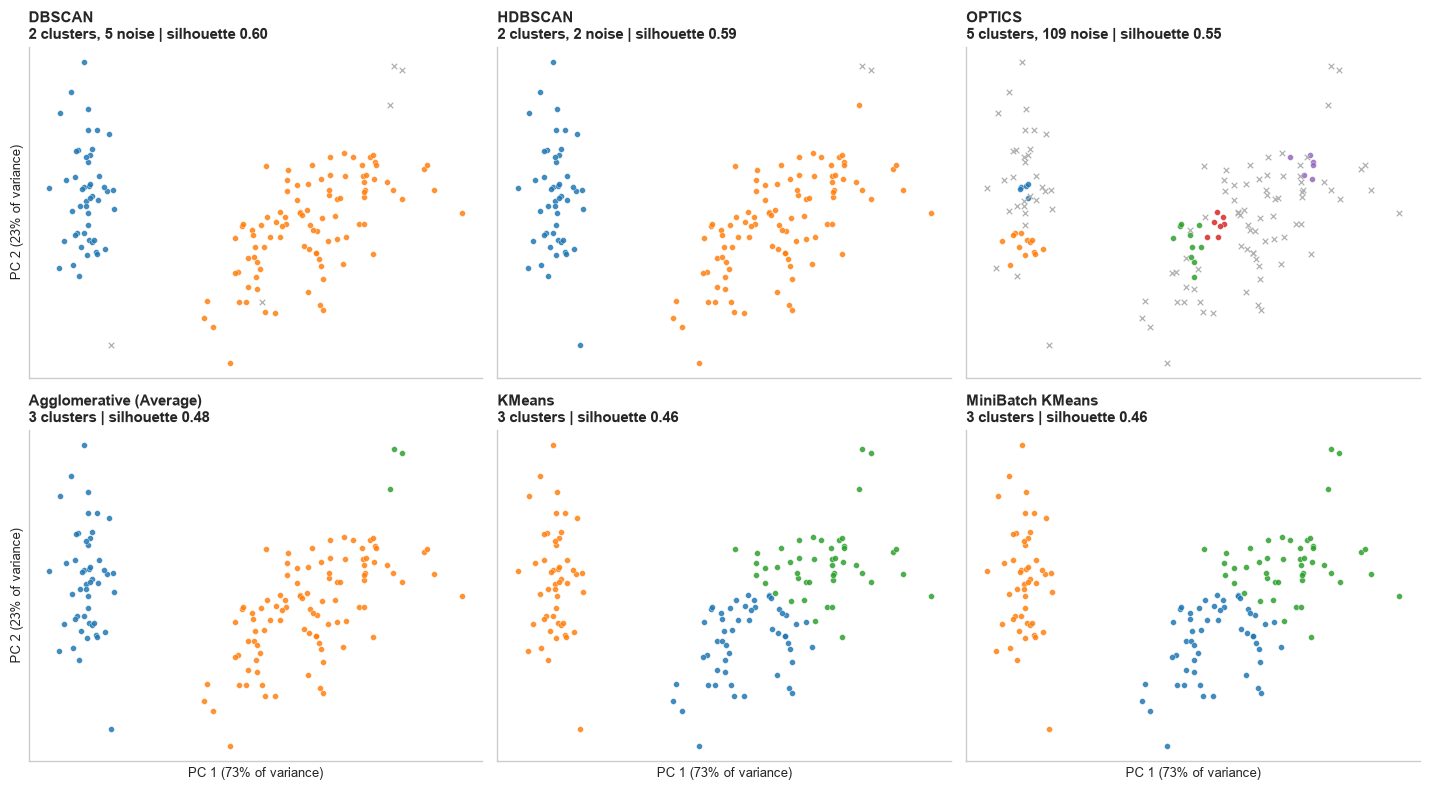

In [13]:
ic.plot_clusters(im, top=6)

In [14]:
ic.cluster_profile('Gaussian Mixture')

,Size,Share (%),sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
cluster,,,,,,
0,45,30.0,5.904444,2.775556,4.193333,1.293333
1,50,33.3,5.006000,3.428000,1.462000,0.246000
2,55,36.7,6.554545,2.950909,5.489091,1.989091


## 5. Shapes k-means cannot handle: two moons with noise
KMeans assumes round clusters. Density-based models (DBSCAN, HDBSCAN) follow any shape and label outliers as **noise (-1)**. Their `eps` is chosen automatically from the data (k-distance rule); see `auto_params_`.

In [15]:
Xm, ym = make_moons(n_samples=400, noise=0.07, random_state=0)
Xm = np.vstack([Xm, [[2.2, 1.6], [-1.4, 1.4], [2.4, -1.2]]])   # three outliers
ym = np.append(ym, [0, 0, 0])
mc = MultiModelClusterer(Xm, y=ym, n_clusters=2, random_state=0, verbose=False)
mmodels = mc.run_all_models(include=['kmeans', 'agglomerative', 'gaussian_mixture', 'spectral', 'dbscan', 'hdbscan'])
mc.show_tabular_report(mmodels, return_df=True, sort_by='ARI')
print('automatic parameters:', mc.auto_params_)


 CLUSTERING MODEL COMPARISON 
               Model  Clusters  Noise Points  Silhouette  Calinski-Harabasz  Davies-Bouldin    ARI    NMI  V-measure  Homogeneity  Completeness  Fit Time (s)
 Spectral Clustering         2             0      0.3812           334.8639          1.0300 0.9901 0.9774     0.9774       0.9774        0.9774        0.0504
             HDBSCAN         2             3      0.3825           338.1866          1.0322 0.9852 0.9728     0.9728       1.0000        0.9470        0.0243
              DBSCAN         3            15      0.0932           198.3269          1.7099 0.8866 0.8302     0.8302       0.9639        0.7291        0.0201
Agglomerative (Ward)         2             0      0.4573           444.7559          0.8470 0.6023 0.5917     0.5917       0.5817        0.6021        0.0016
    Gaussian Mixture         2             0      0.4922           532.9503          0.8101 0.5059 0.4101     0.4101       0.4095        0.4106        0.0221
              KMeans 

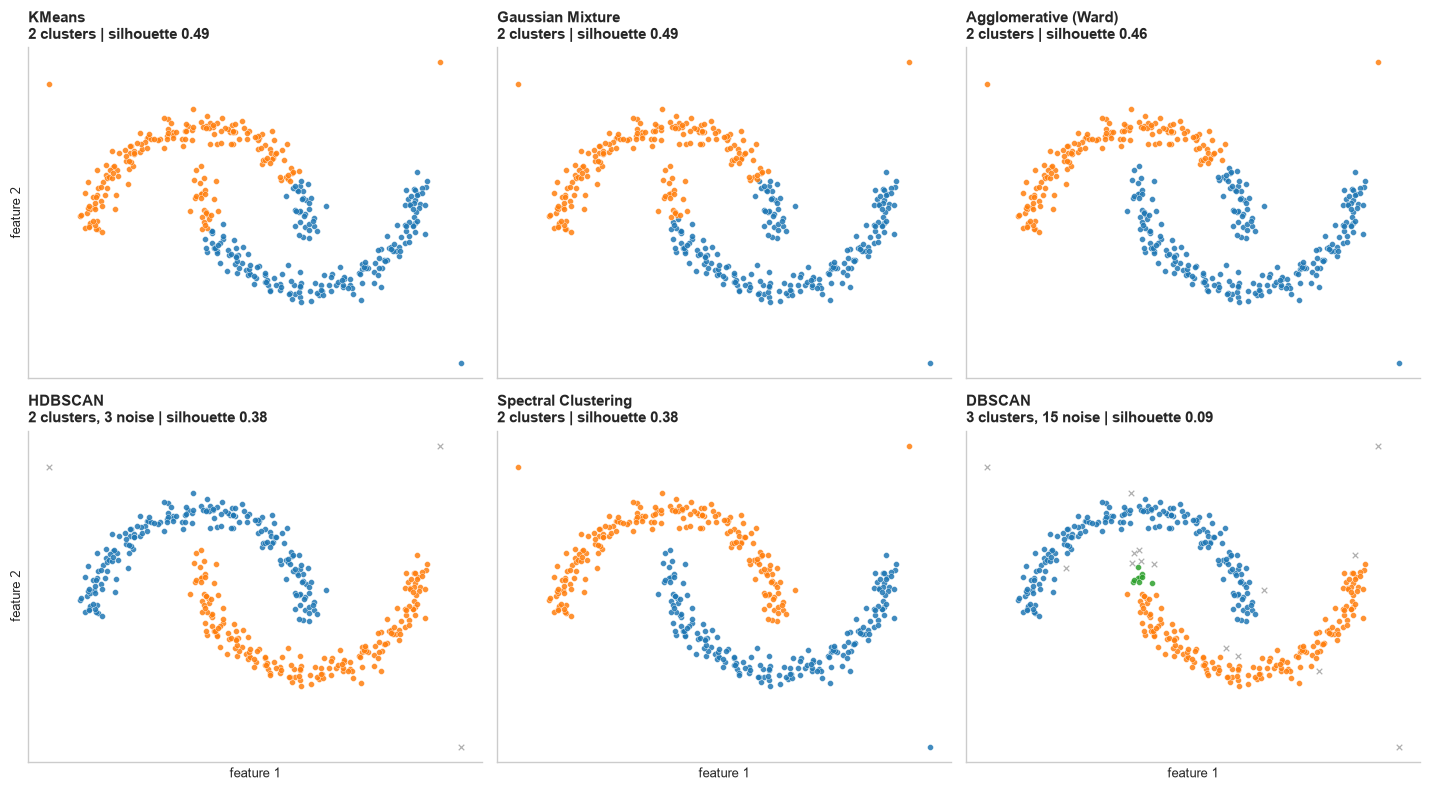

In [16]:
mc.plot_clusters(mmodels, top=6)

Note the trap: the report sorts by **Silhouette** by default, which is geometric and likes round blobs. When you know the truth (or expect odd shapes) look at ARI / the plot, as above. And a model that sets points aside as noise can score higher simply because the hard points are left out - the report warns you when that happens.

## 6. Tuning: `tune_models`
Tries a small grid per model (including different numbers of clusters, DBSCAN `eps` scaled to your data, GMM covariance types, ...) and keeps the combination with the best internal score. Nothing is held out in clustering, so treat scores as comparative rather than absolute.

In [17]:
tuned = cl.tune_models(include=['kmeans', 'gaussian_mixture', 'birch', 'dbscan', 'hdbscan'])
cl.tuning_results_.drop(columns='Best Params')

,Model,Best Silhouette,Candidates,Search Time (s)
0,DBSCAN,0.756934,15,0.313548
1,KMeans,0.749918,9,0.323809
2,Gaussian Mixture,0.749918,36,1.073581
3,Birch,0.749918,36,0.303443
4,HDBSCAN,0.749918,12,0.259748


In [18]:
cl.best_params_

{'KMeans': {'n_clusters': 2},
 'Gaussian Mixture': {'covariance_type': 'full', 'n_clusters': 2},
 'Birch': {'n_clusters': 2, 'threshold': 0.3},
 'DBSCAN': {'eps': 0.2452, 'min_samples': 10},
 'HDBSCAN': {'min_cluster_size': 5, 'min_samples': 5}}

In [19]:
# your own grid, and a different scoring rule
cl.tune_models(include=['dbscan'], scoring='Calinski-Harabasz', param_grids={'dbscan': {'eps': [0.2, 0.3, 0.5], 'min_samples': [4, 8]}})
cl.best_params_

{'DBSCAN': {'eps': 0.2, 'min_samples': 8}}

## 7. Labelling new data: `predict`, `save_model`, `load_model`
Models with a `predict` method (KMeans, MiniBatch KMeans, Gaussian Mixture, Birch, Bisecting KMeans, Mean Shift, Affinity Propagation) can assign **new rows** to clusters; the training scaling is applied for you. DBSCAN, Agglomerative, Spectral, OPTICS and HDBSCAN cannot - you get a clear message instead of a crash.

In [20]:
cl.run_all_models()
new_points = pd.DataFrame({'feature 1': [-6.0, 0.0, 8.0], 'feature 2': [-6.0, 7.0, 0.0]})
print('KMeans         ->', cl.predict(new_points, model='KMeans'))
print('Gauss. Mixture ->', cl.predict(new_points, model='Gaussian Mixture'))
print('no model given ->', cl.predict(new_points), '(the best-ranked model that can predict)')

KMeans         -> [1 0 0]
Gauss. Mixture -> [1 0 2]
no model given -> [1 0 2] (the best-ranked model that can predict)


In [21]:
import os, tempfile
path = cl.save_model(os.path.join(tempfile.mkdtemp(), 'blobs_kmeans.joblib'), model='KMeans')
loaded = mm.load_model(path)
print('reloaded model gives ->', loaded.predict(new_points))

reloaded model gives -> [1 0 0]


In [22]:
try:
    cl.predict(new_points, model='DBSCAN')
except TypeError as e:
    print('TypeError:', e)

TypeError: 'DBSCAN' cannot label new data (it has no predict method). Models that can: ['KMeans', 'MiniBatch KMeans', 'Gaussian Mixture', 'Birch']. Or assign new rows to the nearest cluster yourself.


## 8. Raw data with text columns and gaps: `preprocess=True`
Same switch as the supervised analysers: missing values are filled, text columns one-hot encoded and numbers scaled.

In [23]:
rng = np.random.default_rng(0)
n = 200
customers = pd.DataFrame({
    'age': np.r_[rng.normal(25, 3, n // 2), rng.normal(52, 4, n // 2)],
    'spend': np.r_[rng.normal(300, 40, n // 2), rng.normal(900, 80, n // 2)],
    'plan': np.r_[rng.choice(['basic', 'plus'], n // 2, p=[.8, .2]), rng.choice(['basic', 'plus'], n // 2, p=[.2, .8])],
})
customers.loc[rng.choice(n, 12, replace=False), 'age'] = np.nan
cc = MultiModelClusterer(customers, n_clusters=2, preprocess=True, random_state=0, verbose=False)
cm = cc.run_all_models(include=['kmeans', 'gaussian_mixture', 'agglomerative'])
cc.show_tabular_report(cm, return_df=True)
cc.cluster_profile('KMeans')


 CLUSTERING MODEL COMPARISON 
               Model  Clusters  Noise Points  Silhouette  Calinski-Harabasz  Davies-Bouldin  Fit Time (s)
              KMeans         2             0      0.7258           860.0637          0.4116        0.0239
Agglomerative (Ward)         2             0      0.7258           860.0637          0.4116        0.0012
    Gaussian Mixture         2             0      0.7258           860.0637          0.4116        0.0154

* BEST MODEL (by Silhouette): KMeans  - 2 clusters, Silhouette 0.7258
  Silhouette: above 0.5 = clear groups, 0.25-0.5 = reasonable, below 0.25 = weak structure.
  Davies-Bouldin: lower is better. Noise points (label -1) are left out of the scores.



,Size,Share (%),age,spend
cluster,,,,
0,100,50.0,51.864401,896.877668
1,100,50.0,25.118019,294.480918


## 9. Big data safety, failures and warnings
Spectral, Agglomerative, Affinity Propagation, Mean Shift and OPTICS need O(n^2) memory, so they are **skipped** on large data (reported in `failed_models_`) unless you pass `allow_large=True`. Warnings from scikit-learn are collected in `warnings_` instead of flooding the screen.

Also notice DBSCAN on this bigger data: its automatic `eps` is a heuristic and gave 50 tiny clusters and a negative silhouette, so it ranks last. When a density model looks wrong, run `tune_models` or pass your own `eps` (`run_model('dbscan', eps=...)`).

In [24]:
Xb, _ = make_blobs(n_samples=12000, centers=4, random_state=0)
big = MultiModelClusterer(Xb, n_clusters=4, random_state=0, verbose=False)
bm = big.run_all_models()
big.show_tabular_report(bm, return_df=True)


 CLUSTERING MODEL COMPARISON 
               Model  Clusters  Noise Points  Silhouette  Calinski-Harabasz  Davies-Bouldin  Fit Time (s)
              KMeans         4             0      0.4705         16632.8011          0.7199        0.0331
    MiniBatch KMeans         4             0      0.4702         16631.3131          0.7197        0.0759
    Gaussian Mixture         4             0      0.4663         16223.9889          0.7220        0.0725
Agglomerative (Ward)         4             0      0.4571         15582.8916          0.7343        2.2828
               Birch         4             0      0.3994         13041.5201          0.8211        0.0764
              DBSCAN        50           762     -0.6301            16.0439          0.8478        0.0336

Models that FAILED (not in the table above):
   - Spectral Clustering: skipped: 12000 rows is above 10000; this model needs O(n^2) memory. Use allow_large=True to run it anyway.

* BEST MODEL (by Silhouette): KMeans  - 4 clust

,Model,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin,Fit Time (s)
0,KMeans,4,0,0.470545,16632.801148,0.719881,0.033143
1,MiniBatch KMeans,4,0,0.470217,16631.313117,0.719722,0.075926
2,Gaussian Mixture,4,0,0.466333,16223.988891,0.721993,0.072544
3,Agglomerative (Ward),4,0,0.457114,15582.891578,0.734342,2.282765
4,Birch,4,0,0.399438,13041.520126,0.821093,0.076395
5,DBSCAN,50,762,-0.630131,16.043915,0.847833,0.033642


In [25]:
big.failed_models_

{'Spectral Clustering': 'skipped: 12000 rows is above 10000; this model needs O(n^2) memory. Use allow_large=True to run it anyway.'}

In [26]:
cl.warnings_

{'Spectral Clustering': ['UserWarning: Graph is not fully connected, spectral embedding may not work as expected.']}

## 10. The one-call summary and a saved report
`get_summary()` prints the table and draws the ranking and the cluster scatter plots; `save_prefix` also writes them to disk.

In [27]:
import os, tempfile
out = os.path.join(tempfile.mkdtemp(), 'run')
cl.get_summary(save_prefix=out, show_plot=False)
print(sorted(os.listdir(os.path.dirname(out))))


 CLUSTERING MODEL COMPARISON 
               Model  Clusters  Noise Points  Silhouette  Calinski-Harabasz  Davies-Bouldin    ARI    NMI  V-measure  Homogeneity  Completeness  Fit Time (s)
              DBSCAN         3            16      0.6106          2671.8859          0.6112 0.9142 0.8720     0.8720       0.9174        0.8309        0.0201
 Spectral Clustering         3             0      0.5904          2410.4525          0.6530 0.9606 0.9405     0.9405       0.9405        0.9405        0.0548
    Gaussian Mixture         3             0      0.5898          2401.4931          0.6543 0.9671 0.9488     0.9488       0.9488        0.9488        0.0232
              KMeans         3             0      0.5892          2430.2814          0.6508 0.9167 0.8918     0.8918       0.8918        0.8918        0.0190
    MiniBatch KMeans         3             0      0.5892          2430.2814          0.6508 0.9167 0.8918     0.8918       0.8918        0.8918        0.0284
               Birch 

[INFO] Plot saved to 'C:\Users\uditm\AppData\Local\Temp\tmpwuq3j8y7\run_clusters.png'.
['run_clusters.png', 'run_comparison.png', 'run_report.csv']
